<a href="https://colab.research.google.com/github/FBL9207-source/Python-assessement/blob/main/Classification_casestudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
titanic_data = pd.read_csv("titanic_dataset.csv")
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
titanic_data.set_index('PassengerId', inplace=True)
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Missing values

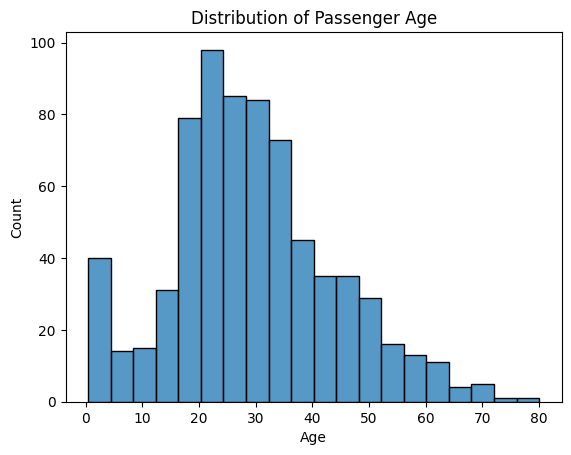

In [5]:
sns.histplot(titanic_data['Age'])
plt.title('Distribution of Passenger Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [6]:
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].median())


In [7]:
titanic_data.drop(columns=['Cabin'], inplace=True, errors='ignore')

In [8]:
most_frequent_embarked = titanic_data['Embarked'].mode()[0]
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(most_frequent_embarked)


In [9]:
titanic_data.drop(['Ticket','Ticket','Name'],axis=1,inplace=True)

In [10]:
titanic_data.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


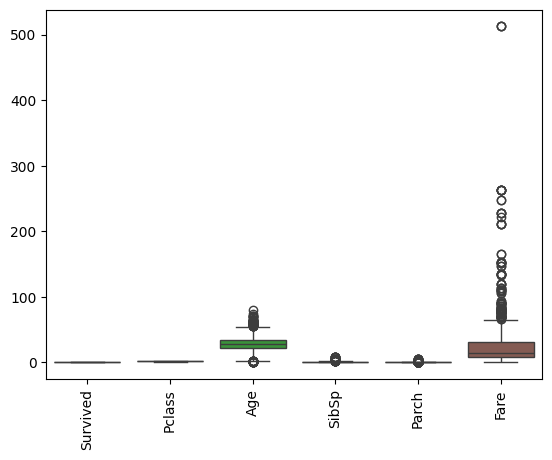

In [11]:
sns.boxplot(titanic_data)
plt.xticks(rotation=90)
plt.show()

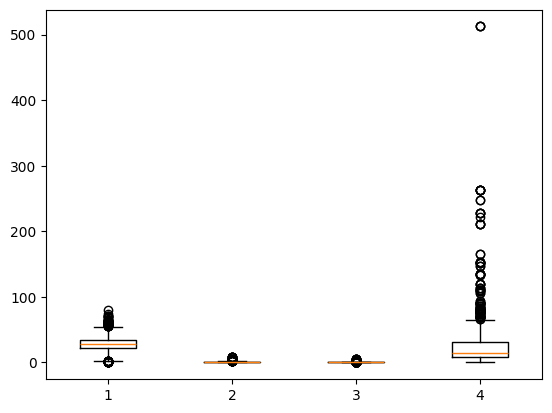

In [12]:
# remove outlires
plt.boxplot(titanic_data[['Age','SibSp','Parch','Fare']])
plt.show()

In [13]:
Q1_age = titanic_data['Age'].quantile(0.25)
Q3_age = titanic_data['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age

Q1_sibsp = titanic_data['SibSp'].quantile(0.25)
Q3_sibsp = titanic_data['SibSp'].quantile(0.75)
IQR_sibsp = Q3_sibsp - Q1_sibsp

lower_bound_sibsp = Q1_sibsp - 1.5 * IQR_sibsp
upper_bound_sibsp = Q3_sibsp + 1.5 * IQR_sibsp

Q1_parch = titanic_data['Parch'].quantile(0.25)
Q3_parch = titanic_data['Parch'].quantile(0.75)
IQR_parch = Q3_parch - Q1_parch

lower_bound_parch = Q1_parch - 1.5 * IQR_parch
upper_bound_parch = Q3_parch + 1.5 * IQR_parch

Q1_fare = titanic_data['Fare'].quantile(0.25)
Q3_fare = titanic_data['Fare'].quantile(0.75)
IQR_fare = Q3_fare - Q1_fare

lower_bound_fare = Q1_fare - 1.5 * IQR_fare
upper_bound_fare = Q3_fare + 1.5 * IQR_fare


In [14]:
titanic_data = titanic_data[
    (titanic_data['Age'] > lower_bound_age) | (titanic_data['Age'] < upper_bound_age) &
    (titanic_data['SibSp'] > lower_bound_sibsp) | (titanic_data['SibSp'] < upper_bound_sibsp) &
    (titanic_data['Parch'] > lower_bound_parch) | (titanic_data['Parch'] < upper_bound_parch) &
    (titanic_data['Fare'] > lower_bound_fare) | (titanic_data['Fare'] < upper_bound_fare)
]

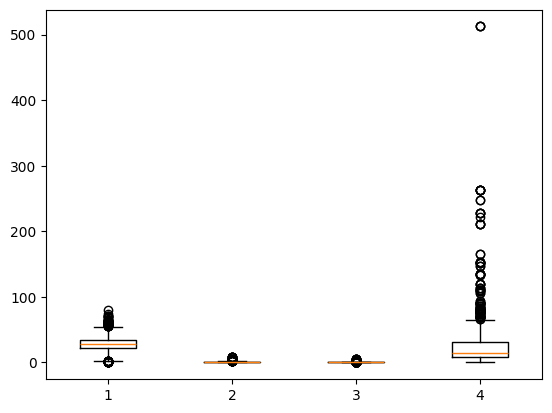

In [15]:
# remove outlires
plt.boxplot(titanic_data[['Age','SibSp','Parch','Fare']])
plt.show()

In [16]:
# Resetting index after dropping outliers
titanic_data.reset_index(drop=True, inplace=True)

In [17]:
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [18]:
titanic_data['Survived'].unique()

array([0, 1])

In [19]:
titanic_data['Embarked'].unique()

array(['S', 'C', 'Q'], dtype=object)

In [20]:
titanic_data.select_dtypes(include=['int','float']).columns

Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

Preprocessing


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [22]:
# seperate x and y
x = titanic_data.drop(['Survived'],axis=1)
y = titanic_data['Survived']

In [23]:
#Train and split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size= 0.2, random_state=42)

In [24]:
num_col = ['Age', 'Fare']
cate_col = ['Embarked','Sex']

In [25]:
# Create the preprocessing pipeline using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cate_col),
        ('num', StandardScaler(),num_col)
    ]
)



In [26]:
# preprocessing pipeline
preprocessing_pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

In [27]:
#Fit and trnsform training data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed  = preprocessor.transform(x_test)

#logistic regression

In [28]:
#Logistic Regression model
lr_model =LogisticRegression(max_iter=1000)
lr_model.fit(x_train_processed,y_train)
y_pred_lr_model=lr_model.predict(x_test_processed)

In [29]:
from sklearn.metrics import confusion_matrix,precision_score
from sklearn.metrics import accuracy_score,f1_score
from sklearn.metrics import recall_score

In [30]:
print(confusion_matrix(y_test, y_pred_lr_model))
print('Accuracy is:', accuracy_score(y_test, y_pred_lr_model))
print('Precision is:', precision_score(y_test, y_pred_lr_model))
print('F1 score is:', f1_score(y_test, y_pred_lr_model))
print('Recall score is:', recall_score(y_test, y_pred_lr_model))

[[87 18]
 [22 52]]
Accuracy is: 0.776536312849162
Precision is: 0.7428571428571429
F1 score is: 0.7222222222222222
Recall score is: 0.7027027027027027


#KNN


In [32]:
# Finding the optimum k value
from sklearn.neighbors import KNeighborsClassifier

acc_score =[]
for i in range(3,10):
  knn= KNeighborsClassifier(n_neighbors=i)
  knn.fit(x_train_processed,y_train)
  y_pred_knn=knn.predict(x_test_processed)
  acc=accuracy_score(y_test,y_pred_knn)
  acc_score.append(acc)

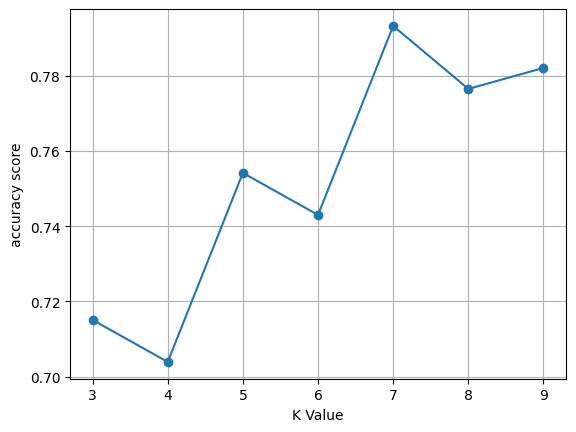

In [33]:
plt.plot(np.arange(3,10),acc_score,'o-')
plt.xlabel('K Value')
plt.ylabel('accuracy score')
plt.grid()

In [35]:
#optimum k value is 5 because accuracy is high when k = 7
#train the knn model for k = %
knn  = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train_processed,y_train)
y_pred_knn = knn.predict(x_test_processed)
print(confusion_matrix(y_test,y_pred_knn))
print("Accuracy is : " ,accuracy_score(y_test,y_pred_knn))
print("Precision is : ",precision_score(y_test,y_pred_knn))
print("Recall is : ",recall_score(y_test,y_pred_knn))
print("F1 score is : ",f1_score(y_test,y_pred_knn))

[[88 17]
 [20 54]]
Accuracy is :  0.7932960893854749
Precision is :  0.7605633802816901
Recall is :  0.7297297297297297
F1 score is :  0.7448275862068966


#SVM


In [36]:
from sklearn.svm import SVC

In [37]:
#Linear kernel
svm_linear = SVC(kernel="linear")
svm_linear.fit(x_train_processed,y_train)
y_pred_svm_linear = svm_linear.predict(x_test_processed)
print(confusion_matrix(y_test,y_pred_svm_linear))
print(accuracy_score(y_test,y_pred_svm_linear))
print(recall_score(y_test,y_pred_svm_linear))
print(f1_score(y_test,y_pred_svm_linear))

[[88 17]
 [22 52]]
0.7821229050279329
0.7027027027027027
0.7272727272727273


In [38]:
#polynomial kernel

svm_poly = SVC(kernel="poly")
svm_poly.fit(x_train_processed,y_train)
y_pred_svm_poly = svm_poly.predict(x_test_processed)
print(confusion_matrix(y_test,y_pred_svm_poly))
print(accuracy_score(y_test,y_pred_svm_poly))
print(recall_score(y_test,y_pred_svm_poly))
print(f1_score(y_test,y_pred_svm_poly))

[[87 18]
 [21 53]]
0.7821229050279329
0.7162162162162162
0.7310344827586207


In [39]:
#rbf kernel

svm_rbf = SVC(kernel="rbf")
svm_rbf.fit(x_train_processed,y_train)
y_pred_svm_rbf = svm_rbf.predict(x_test_processed)
print(confusion_matrix(y_test,y_pred_svm_rbf))
print(accuracy_score(y_test,y_pred_svm_rbf))
print(recall_score(y_test,y_pred_svm_rbf))
print(f1_score(y_test,y_pred_svm_rbf))

[[87 18]
 [21 53]]
0.7821229050279329
0.7162162162162162
0.7310344827586207


#Decision Tree

In [40]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion = "entropy", random_state = 42)
dt.fit(x_train_processed,y_train)
y_pred_dt = dt.predict(x_test_processed)
print(confusion_matrix(y_test,y_pred_dt))
print(accuracy_score(y_test,y_pred_dt))
print(precision_score(y_test,y_pred_dt))
print(recall_score(y_test,y_pred_dt))
print(f1_score(y_test,y_pred_dt))

[[87 18]
 [23 51]]
0.770949720670391
0.7391304347826086
0.6891891891891891
0.7132867132867133


#Random Forest

In [41]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(criterion="entropy", random_state= 42)
rf.fit(x_train_processed,y_train)
y_pred_rf = rf.predict(x_test_processed)
print(confusion_matrix(y_test,y_pred_rf))
print(accuracy_score(y_test,y_pred_rf))
print(precision_score(y_test,y_pred_rf))
print(recall_score(y_test,y_pred_rf))
print(f1_score(y_test,y_pred_rf))

[[83 22]
 [21 53]]
0.7597765363128491
0.7066666666666667
0.7162162162162162
0.7114093959731543
